In [ ]:
#  Preliminary analysis
import pandas as pd

# Load datasets
items = pd.read_csv('c:/data/items.csv')
restaurants = pd.read_csv('c:/data/resturants.csv')
sales = pd.read_csv('c:/data/sales.csv')

# Check shape and structure
print("Items Dataset Shape:", items.shape)
print("Items Columns:", items.columns)
print(items.head())

print("Restaurants Dataset Shape:", restaurants.shape)
print("Restaurants Columns:", restaurants.columns)
print(restaurants.head())

print("Sales Dataset Shape:", sales.shape)
print("Sales Columns:", sales.columns)
print(sales.head())

Items Dataset Shape: (100, 5)
Items Columns: Index(['id', 'store_id', 'name', 'kcal', 'cost'], dtype='object')
   id  store_id                               name  kcal   cost
0   1         4                     Chocolate Cake   554   6.71
1   2         4  Breaded Fish with Vegetables Meal   772  15.09
2   3         1                  Sweet Fruity Cake   931  29.22
3   4         1    Amazing Steak Dinner with Rolls   763  26.42
4   5         5                          Milk Cake   583   6.07
Restaurants Dataset Shape: (6, 2)
Restaurants Columns: Index(['id', 'name'], dtype='object')
   id            name
0   1     Bob's Diner
1   2  Beachfront Bar
2   3     Sweet Shack
3   4        Fou Cher
4   5     Corner Cafe
Sales Dataset Shape: (109600, 4)
Sales Columns: Index(['date', 'item_id', 'item_count', 'price'], dtype='object')
         date  item_id  item_count   price
0  01-01-2019        3           2   58.44
1  01-01-2019        4          22  581.24
2  01-01-2019       12           7   

In [ ]:
# Outlier Detection
print("Items Dataset Summary:")
print(items.describe())
print('Number of rows in Items Dataset:', len(items))

print("restaurants Dataset Summary:")
print(restaurants.describe())
print('Number of rows in Restaurants Dataset:',len(restaurants))

print("Sales Dataset Summary:")
print(sales.describe())
print('Number of rows in Sales Dataset:',len(sales))


Items Dataset Summary:
               id    store_id         kcal        cost
count  100.000000  100.000000   100.000000  100.000000
mean    50.500000    3.520000   536.730000   11.763700
std     29.011492    1.708446   202.212852    8.991254
min      1.000000    1.000000    78.000000    1.390000
25%     25.750000    2.000000   406.250000    5.280000
50%     50.500000    4.000000   572.500000    7.625000
75%     75.250000    5.000000   638.250000   18.790000
max    100.000000    6.000000  1023.000000   53.980000
Number of rows in Items Dataset: 100
restaurants Dataset Summary:
             id
count  6.000000
mean   3.500000
std    1.870829
min    1.000000
25%    2.250000
50%    3.500000
75%    4.750000
max    6.000000
Number of rows in Restaurants Dataset: 6
Sales Dataset Summary:
             item_id     item_count          price
count  109600.000000  109600.000000  109600.000000
mean       50.500000       6.339297      58.428271
std        28.866202      30.003728     214.812200
min 

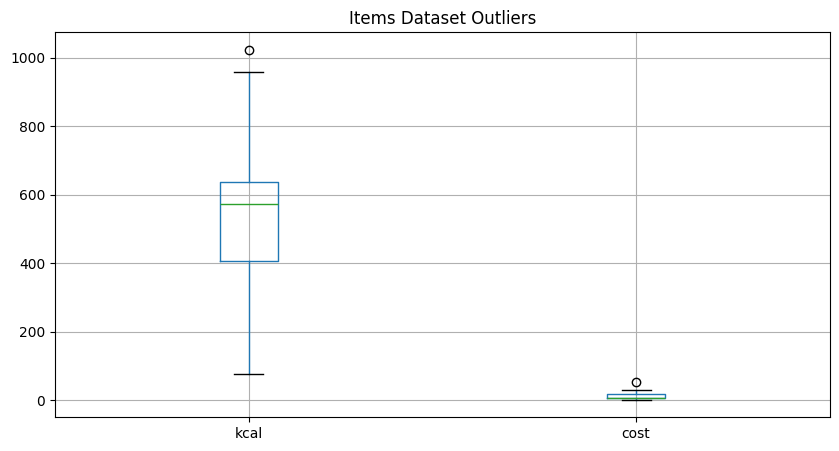

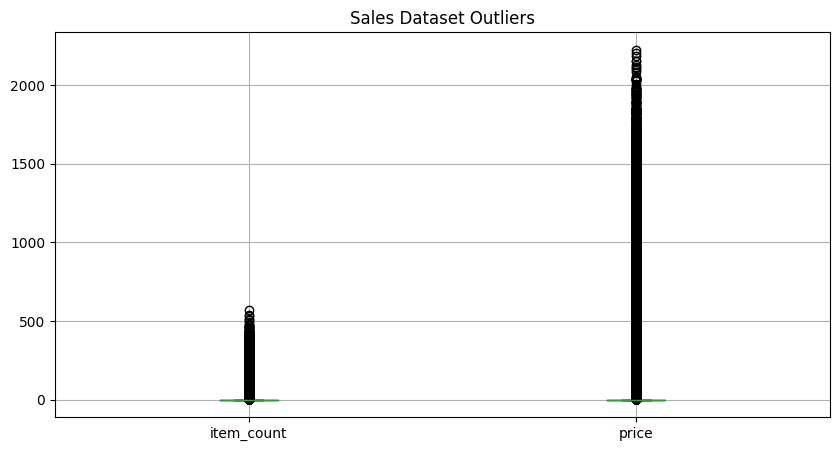

In [ ]:
import matplotlib.pyplot as plt

items.boxplot(column=['kcal', 'cost'], figsize=(10, 5))
plt.title("Items Dataset Outliers")
plt.show()

sales.boxplot(column=['item_count', 'price'], figsize=(10, 5))
plt.title("Sales Dataset Outliers")
plt.show()

# the Items Dataset outliers box plot chart highlights outliers in the items dataset for the kcal and cost variables
kcal:

Median is approximately 600.

Interquartile range (IQR) spans from around 450 to 700.

There's a clear outlier at 1000, suggesting extreme values in the dataset.

cost:

Median is close to 0.

Very narrow interquartile range, indicating most values are tightly clustered near the median.

An outlier exists around 10, which deviates significantly from the rest of the data.

These observations highlight the need to address outliers, either through removal, imputation, or transformation

# the Items Dataset outliers box plot chart highlights outliers in the sales dataset for the item_count and price

item_count:

Most values are tightly clustered around the lower range, as the box plot is close to the x-axis.

Outliers are indicated as points far above the box plot, suggesting some instances where the item count is unusually high.

price:

Similar behavior is observed, with most values concentrated near the lower range.

Outliers appear as extreme values, shown as points above the box plot

These observations highlight the need to address outliers, either through removal, imputation, or transformation



In [ ]:
merged_df = sales.merge(items, left_on='item_id', right_on='id', how='inner')

In [ ]:
final_df = merged_df.merge(restaurants, left_on='store_id', right_on='id', how='inner')
final_df.head()

,date,item_id,item_count,price,id_x,store_id,name_x,kcal,cost,id_y,name_y
0,01-01-2019,3,2,58.44,3,1,Sweet Fruity Cake,931,29.22,1,Bob's Diner
1,01-01-2019,4,22,581.24,4,1,Amazing Steak Dinner with Rolls,763,26.42,1,Bob's Diner
2,01-01-2019,12,7,34.09,12,1,Fantastic Sweet Cola,478,4.87,1,Bob's Diner
3,01-01-2019,13,12,50.16,13,1,Sweet Frozen Soft Drink,490,4.18,1,Bob's Diner
4,01-01-2019,16,136,436.56,16,1,Frozen Milky Smoothy,284,3.21,1,Bob's Diner


In [ ]:
print(final_df.columns)
final_df = final_df[['date', 'item_id', 'item_count', 'price', 'name_x', 'kcal', 'id_y', 'name_y']]
final_df = final_df.rename(columns={'name_x': 'item names', 'item_id': 'item id', 'item_count': 'item count', 'kcal': 'kcal values', 'id_y': 'store id', 'name_y': 'store name'})
final_df.head()

Index(['date', 'item_id', 'item_count', 'price', 'id_x', 'store_id', 'name_x',
       'kcal', 'cost', 'id_y', 'name_y'],
      dtype='object')


,date,item id,item count,price,item names,kcal values,store id,store name
0,01-01-2019,3,2,58.44,Sweet Fruity Cake,931,1,Bob's Diner
1,01-01-2019,4,22,581.24,Amazing Steak Dinner with Rolls,763,1,Bob's Diner
2,01-01-2019,12,7,34.09,Fantastic Sweet Cola,478,1,Bob's Diner
3,01-01-2019,13,12,50.16,Sweet Frozen Soft Drink,490,1,Bob's Diner
4,01-01-2019,16,136,436.56,Frozen Milky Smoothy,284,1,Bob's Diner


In [ ]:
#  Exploratory data analysis
#  to examine the overall date wise sales to understand the pattern
# Aggregate Sales Data by Date

# Create a new column for total daily sales
daily_sales = final_df.groupby('date')['price'].sum().reset_index()
daily_sales.rename(columns={'price': 'total_sales'}, inplace=True)

# Merge total_sales back to the original DataFrame
final_df = final_df.merge(daily_sales, on='date', how='left')

# Check the updated DataFrame
print(final_df.head())

         date  item id  item count   price                       item names  \
0  01-01-2019        3           2   58.44                Sweet Fruity Cake   
1  01-01-2019        4          22  581.24  Amazing Steak Dinner with Rolls   
2  01-01-2019       12           7   34.09             Fantastic Sweet Cola   
3  01-01-2019       13          12   50.16          Sweet Frozen Soft Drink   
4  01-01-2019       16         136  436.56             Frozen Milky Smoothy   

   kcal values  store id   store name  total_sales  
0          931         1  Bob's Diner       4023.0  
1          763         1  Bob's Diner       4023.0  
2          478         1  Bob's Diner       4023.0  
3          490         1  Bob's Diner       4023.0  
4          284         1  Bob's Diner       4023.0  


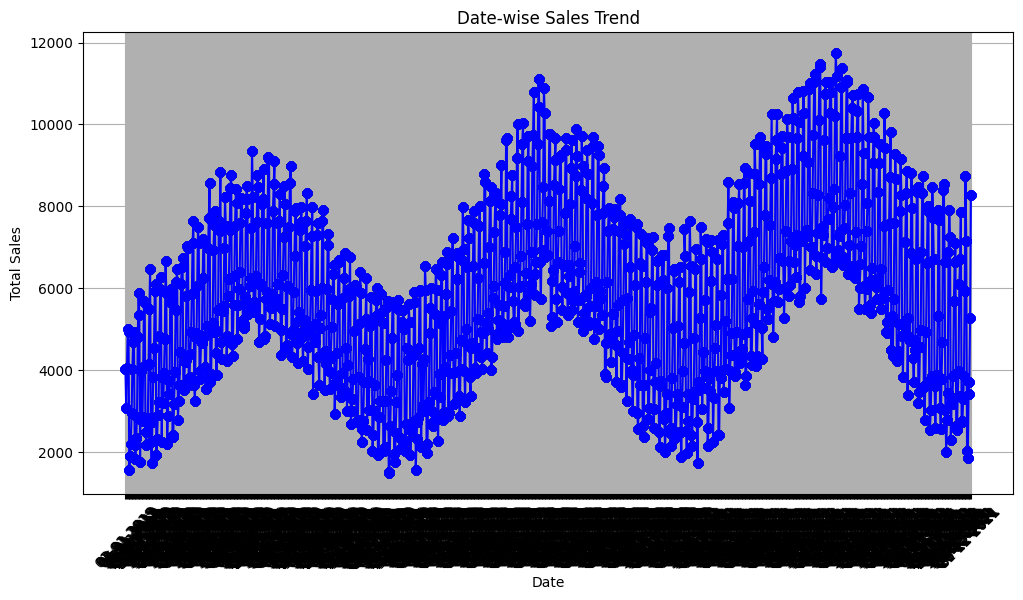

In [ ]:
#Visualize the Date-Wise Sales Trend
# Plot the date-wise total sales trend
plt.figure(figsize=(12, 6))
plt.plot(final_df['date'], final_df['total_sales'], marker='o', linestyle='-', color='b')
plt.title('Date-wise Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid()
plt.show()

The line graph illustrates the "Date-wise Sales Trend", where sales data is plotted over time. Here are key observations:

Cyclical Patterns: The graph reveals clear fluctuations, with peaks and troughs that could represent specific time periods of high or low demand (e.g., weekends, holidays, or events).

Peaks and Troughs: There are noticeable high points where sales spike, as well as low points with reduced sales activity.

Sales Range: The y-axis spans from 0 to 12000, and the highest observed sales approach the upper end of this range, indicating significant variation in daily totals.

In [ ]:
# Ensure the date column matches the format in data frame
final_df['date'] = pd.to_datetime(final_df['date'], format='%d-%m-%Y')

# Check the updated DataFrame
print(final_df[['date']].head())

final_df['date'] = pd.to_datetime(final_df['date'], dayfirst=True)  # Assumes day is the first part of the date


        date
0 2019-01-01
1 2019-01-01
2 2019-01-01
3 2019-01-01
4 2019-01-01


In [ ]:
#sales fluctuate across different days of the week

final_df['date'] = pd.to_datetime(final_df['date'])

# Add a column for day of the week
final_df['day_of_week'] = final_df['date'].dt.day_name()

# Check the updated DataFrame
print(final_df[['date', 'day_of_week']].head())

        date day_of_week
0 2019-01-01     Tuesday
1 2019-01-01     Tuesday
2 2019-01-01     Tuesday
3 2019-01-01     Tuesday
4 2019-01-01     Tuesday


In [ ]:
# Aggregate Sales by Day of the Week
# Group sales by day of the week
day_wise_sales = final_df.groupby('day_of_week').agg({'price': 'sum'}).reset_index()
day_wise_sales.rename(columns={'price': 'total_sales'}, inplace=True)

# Sort the days of the week for better visualization
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_wise_sales['day_of_week'] = pd.Categorical(day_wise_sales['day_of_week'], categories=ordered_days, ordered=True)
day_wise_sales = day_wise_sales.sort_values('day_of_week')

# Display the aggregated data
print(day_wise_sales)

  day_of_week  total_sales
1      Monday    644799.97
5     Tuesday    734598.46
6   Wednesday    812613.31
4    Thursday   1073534.52
0      Friday   1257338.16
2    Saturday   1250574.32
3      Sunday    630279.71


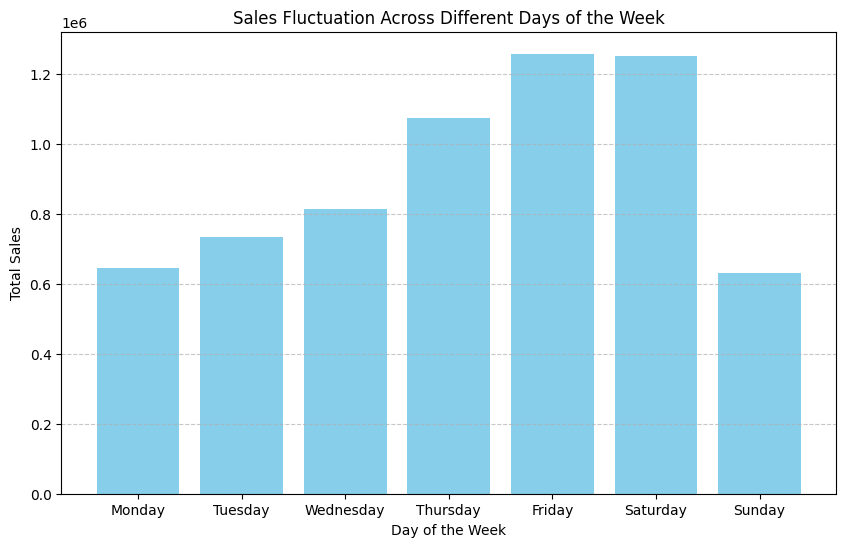

In [ ]:
# Visualize Sales Patterns
# Plot total sales by day of the week
plt.figure(figsize=(10, 6))
plt.bar(day_wise_sales['day_of_week'], day_wise_sales['total_sales'], color='skyblue')
plt.title('Sales Fluctuation Across Different Days of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Sales')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The bar chart illustrates "Sales Fluctuation Across Different Days of the Week", showcasing total sales for each day. Here's a summary of insights:

Peak Sales Days:

Sales are highest on Friday and Saturday, both reaching approximately 1.2 million (1.2e6). This suggests these days could be critical for business strategies, such as promotions or stocking inventory.

Low Sales Days:

The lowest sales occur on Monday and Sunday, each hovering around 0.6 million. These might represent quieter periods in demand.

Gradual Increase Midweek:

Sales climb steadily from Monday through Thursday, indicating a growing trend toward the weekend.


In [ ]:
# Extract the Month
# Ensure 'date' is in datetime format
final_df['date'] = pd.to_datetime(final_df['date'])

# Extract the month name
final_df['month'] = final_df['date'].dt.month_name()

# Check the updated DataFrame
print(final_df[['date', 'month']].head())

        date    month
0 2019-01-01  January
1 2019-01-01  January
2 2019-01-01  January
3 2019-01-01  January
4 2019-01-01  January


In [ ]:
# Aggregate Sales Data by Month
# Aggregate sales by month
month_wise_sales = final_df.groupby('month').agg({'price': 'sum'}).reset_index()
month_wise_sales.rename(columns={'price': 'total_sales'}, inplace=True)

# Sort months in chronological order
ordered_months = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
month_wise_sales['month'] = pd.Categorical(month_wise_sales['month'], categories=ordered_months, ordered=True)
month_wise_sales = month_wise_sales.sort_values('month')

# Display the aggregated data
print(month_wise_sales)

        month  total_sales
4     January    375778.02
3    February    394527.38
7       March    498218.89
0       April    571458.39
8         May    666063.17
6        June    691116.06
5        July    706038.79
1      August    647024.97
11  September    548927.39
10    October    501292.21
9    November    412535.86
2    December    390757.32


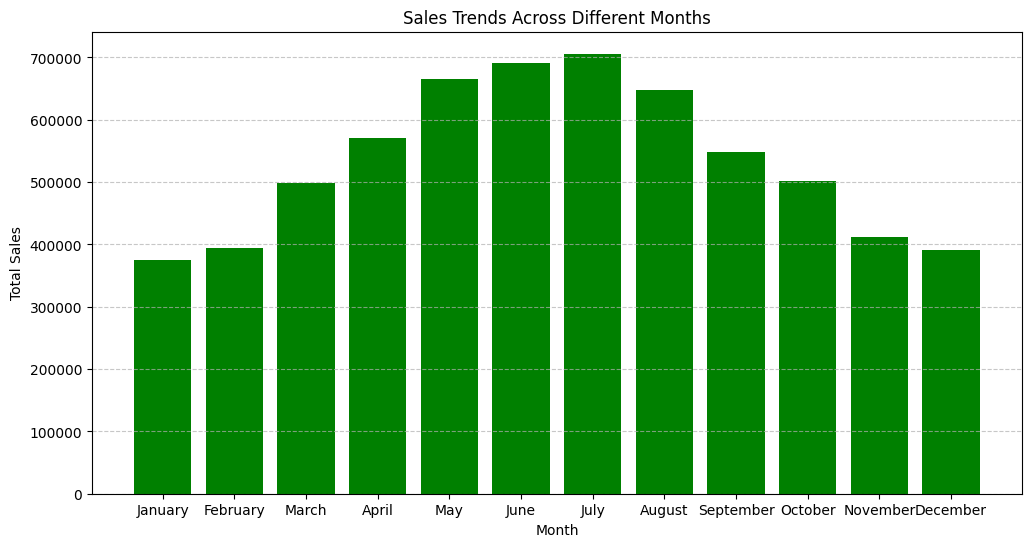

In [ ]:
# Visualize Sales Trends by Month
# Plot sales by month
plt.figure(figsize=(12, 6))
plt.bar(month_wise_sales['month'], month_wise_sales['total_sales'], color='green')
plt.title('Sales Trends Across Different Months')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The bar chart, titled "Sales Trends Across Different Months," showcases total sales for each month from January to December. below are key observatios:

Peak Sales Period:

Sales reach their highest in July, nearing 800,000. This indicates a significant surge, potentially due to seasonal demand or promotions.

Lowest Sales Period:

The lowest sales occur in December, falling below 200,000. This drop might indicate reduced activity or the end of a business cycle.

Steady Growth and Decline:

Sales grow steadily from January to July before tapering off towards December.

In [ ]:
# Extract Quarter Information
# Ensure 'date' is in datetime format
final_df['date'] = pd.to_datetime(final_df['date'])

# Extract the quarter
final_df['quarter'] = final_df['date'].dt.quarter

# Check the updated DataFrame
print(final_df[['date', 'quarter']].head())

        date  quarter
0 2019-01-01        1
1 2019-01-01        1
2 2019-01-01        1
3 2019-01-01        1
4 2019-01-01        1


In [ ]:
# Aggregate Sales by Quarter
# Group sales by quarter
quarterly_sales = final_df.groupby('quarter').agg({'price': 'mean'}).reset_index()
quarterly_sales.rename(columns={'price': 'average_sales'}, inplace=True)

# Display the aggregated data
print(quarterly_sales)

   quarter  average_sales
0        1      46.809014
1        2      70.646067
2        3      68.912723
3        4      47.267587


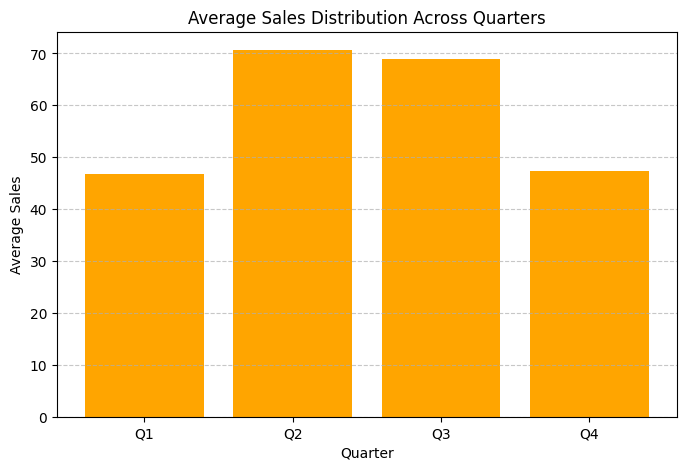

In [ ]:
# Visualize Sales Patterns by Quarter
# Plot sales by quarter
plt.figure(figsize=(8, 5))
plt.bar(quarterly_sales['quarter'], quarterly_sales['average_sales'], color='orange')
plt.title('Average Sales Distribution Across Quarters')
plt.xlabel('Quarter')
plt.ylabel('Average Sales')
plt.xticks([1, 2, 3, 4], ['Q1', 'Q2', 'Q3', 'Q4'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The bar chart depicts the "Average Sales Distribution Across Quarters". below are analysis:

Highest Average Sales:

Quarter 2 (Q2) leads with the highest average sales, reaching 70. This might indicate a period of heightened demand or significant sales activities.

Moderately High Average Sales:

Quarter 3 (Q3) follows closely with an average of 65, suggesting sustained strong performance during this period.

Lowest Average Sales:

Quarters 1 (Q1) and 4 (Q4) have the same average sales of 45, indicating relatively lower activity compared to Q2 and Q3.

In [ ]:
# Group total sales by restaurant
restaurant_sales = final_df.groupby('store name').agg({'price': 'sum'}).reset_index()
restaurant_sales.rename(columns={'price': 'total_sales'}, inplace=True)

# Identify the restaurant with the most sales
top_restaurant = restaurant_sales.loc[restaurant_sales['total_sales'].idxmax()]

# Display results
print("Total sales by restaurant:")
print(restaurant_sales)
print("\nRestaurant with the most sales:")
print(top_restaurant)

Total sales by restaurant:
       store name  total_sales
0  Beachfront Bar      3796.20
1     Bob's Diner   6337275.69
2     Corner Cafe     16551.43
3        Fou Cher     27885.37
4        Surfs Up     15651.49
5     Sweet Shack      2578.27

Restaurant with the most sales:
store name     Bob's Diner
total_sales     6337275.69
Name: 1, dtype: object


In [ ]:
# Analyze Sales by Year
# Extract year from date
final_df['year'] = final_df['date'].dt.year

# Group sales by restaurant and year
yearly_sales = final_df.groupby(['store name', 'year']).agg({'price': 'sum'}).reset_index()
yearly_sales.rename(columns={'price': 'yearly_sales'}, inplace=True)

# Display yearly sales
print("Yearly sales by restaurant:")
print(yearly_sales)

Yearly sales by restaurant:
        store name  year  yearly_sales
0   Beachfront Bar  2019       1281.85
1   Beachfront Bar  2020       1267.21
2   Beachfront Bar  2021       1247.14
3      Bob's Diner  2019    1849483.49
4      Bob's Diner  2020    2112331.91
5      Bob's Diner  2021    2375460.29
6      Corner Cafe  2019       5292.93
7      Corner Cafe  2020       5347.71
8      Corner Cafe  2021       5910.79
9         Fou Cher  2019       9698.80
10        Fou Cher  2020       8590.87
11        Fou Cher  2021       9595.70
12        Surfs Up  2019       5132.65
13        Surfs Up  2020       5314.43
14        Surfs Up  2021       5204.41
15     Sweet Shack  2019        872.59
16     Sweet Shack  2020        828.65
17     Sweet Shack  2021        877.03


In [ ]:
# Analyze Sales by Month
# Extract month from date
final_df['month'] = final_df['date'].dt.month_name()

# Group sales by restaurant and month
monthly_sales = final_df.groupby(['store name', 'month']).agg({'price': 'sum'}).reset_index()
monthly_sales.rename(columns={'price': 'monthly_sales'}, inplace=True)

# Display monthly sales
print("Monthly sales by restaurant:")
print(monthly_sales)

Monthly sales by restaurant:
        store name      month  monthly_sales
0   Beachfront Bar      April         317.58
1   Beachfront Bar     August         284.38
2   Beachfront Bar   December         390.13
3   Beachfront Bar   February         318.10
4   Beachfront Bar    January         315.55
..             ...        ...            ...
67     Sweet Shack      March         215.91
68     Sweet Shack        May         234.47
69     Sweet Shack   November         199.38
70     Sweet Shack    October         224.80
71     Sweet Shack  September         214.06

[72 rows x 3 columns]


In [ ]:
# Analyze Sales by Day
# Group sales by restaurant and day
daily_sales = final_df.groupby(['store name', 'date']).agg({'price': 'sum'}).reset_index()
daily_sales.rename(columns={'price': 'daily_sales'}, inplace=True)

# Display daily sales
print("Daily sales by restaurant:")
print(daily_sales)

Daily sales by restaurant:
          store name       date  daily_sales
0     Beachfront Bar 2019-01-01         2.91
1     Beachfront Bar 2019-01-02         2.91
2     Beachfront Bar 2019-01-03         2.91
3     Beachfront Bar 2019-01-04         5.34
4     Beachfront Bar 2019-01-05         2.91
...              ...        ...          ...
6571     Sweet Shack 2021-12-27         2.78
6572     Sweet Shack 2021-12-28         0.00
6573     Sweet Shack 2021-12-29         2.78
6574     Sweet Shack 2021-12-30         0.00
6575     Sweet Shack 2021-12-31         0.00

[6576 rows x 3 columns]


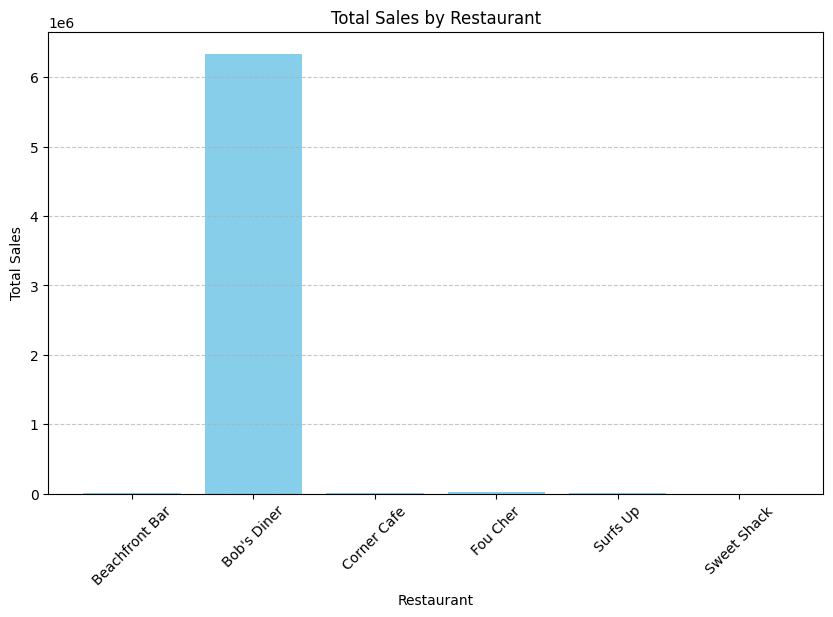

In [ ]:
# Plot total sales by restaurant
plt.figure(figsize=(10, 6))
plt.bar(restaurant_sales['store name'], restaurant_sales['total_sales'], color='skyblue')
plt.title('Total Sales by Restaurant')
plt.xlabel('Restaurant')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The bar chart provides a comparison of total sales across six restaurants. below are the observations

Bob's Diner:

Dominates the chart with sales reaching 6,000,000. It's significantly ahead of all other restaurants, accounting for the majority of total sales.

Other Restaurants:

Restaurants like Beachfront Bar, Corner Cafe, Fou Cher, Surfs Up, and Sweet Snack have comparatively negligible sales.

These restaurants show much lower contributions to overall sales.

Sales Gap: Bob's Diner outperforms its competitors by an overwhelming margin. The other restaurants could analyze its strategies to identify key drivers of success.

Focus Areas: For underperforming restaurants, targeted efforts (e.g., promotions, menu updates, customer engagement) may help boost their sales

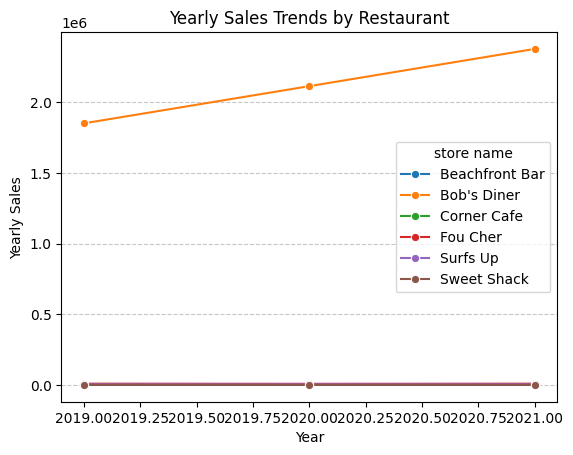

In [ ]:
# Plot yearly sales trends for each restaurant
import seaborn as sns
sns.lineplot(data=yearly_sales, x='year', y='yearly_sales', hue='store name', marker='o')
plt.title('Yearly Sales Trends by Restaurant')
plt.xlabel('Year')
plt.ylabel('Yearly Sales')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The line graph depicts sales trajectories for six restaurants over three years (2019–2021). Here are key insights:

Bob's Diner Dominates:

Bob's Diner shows a clear upward trend in sales, significantly outperforming other restaurants.

This suggests its consistent growth and leadership in sales across the years.

Other Restaurants:

Beachfront Bar, Corner Cafe, Fou Cher, Surfs Up, and Sweet Shack exhibit sales near zero, with minimal fluctuations.

These restaurants may need strategic interventions to improve performance.

Sales Gap:

The disparity between Bob's Diner and the other establishments is stark, highlighting its competitive edge.

In [ ]:
# Machine learning
# Identify the Most Popular Items Overall
# Group by item names to calculate total count sold
popular_items = final_df.groupby('item names').agg({'item count': 'sum'}).reset_index()
popular_items.rename(columns={'item count': 'total_count'}, inplace=True)

# Sort by total count in descending order
popular_items = popular_items.sort_values('total_count', ascending=False)

# Display the top items
print("Most Popular Items Overall:")
print(popular_items.head())

Most Popular Items Overall:
              item names  total_count
85    Strawberry Smoothy       236337
46  Frozen Milky Smoothy       103263
9     Amazing pork lunch        61043
64         Mutton Dinner        52772
67          Orange Juice        43874


In [ ]:
# Identify Stores Where Popular Items are Sold
# Find stores where popular items are sold
stores_selling_popular_items = final_df[final_df['item names'].isin(popular_items['item names'].head(5))]
popular_items_with_stores = stores_selling_popular_items[['item names', 'store name']].drop_duplicates()

# Display the results
print("Stores Selling Popular Items:")
print(popular_items_with_stores)

Stores Selling Popular Items:
              item names   store name
4   Frozen Milky Smoothy  Bob's Diner
5     Strawberry Smoothy  Bob's Diner
17    Amazing pork lunch  Bob's Diner
27          Orange Juice  Bob's Diner
48         Mutton Dinner  Bob's Diner
76  Frozen Milky Smoothy  Corner Cafe


In [ ]:
# Identify the Most Popular Item at Each Store
# Group by store name and item names to calculate total count
store_item_sales = final_df.groupby(['store name', 'item names']).agg({'item count': 'sum'}).reset_index()
store_item_sales.rename(columns={'item count': 'total_count'}, inplace=True)

# Find the most popular item for each store
most_popular_item_per_store = store_item_sales.loc[store_item_sales.groupby('store name')['total_count'].idxmax()]

# Display the results
print("Most Popular Item at Each Store:")
print(most_popular_item_per_store)

Most Popular Item at Each Store:
        store name                     item names  total_count
1   Beachfront Bar        Fantastic Milky Smoothy         1147
25     Bob's Diner             Strawberry Smoothy       236337
40     Corner Cafe           Frozen Milky Smoothy          273
57        Fou Cher  Blue Ribbon Fruity Vegi Lunch          298
85        Surfs Up             Awesome Soft Drink          997
92     Sweet Shack                Awesome Smoothy         1692


In [ ]:
# Identify the Store with the Highest Sales Volume
# Group by store name and calculate total item count
store_sales_volume = final_df.groupby('store name').agg({'item count': 'sum'}).reset_index()
store_sales_volume.rename(columns={'item count': 'total_volume'}, inplace=True)

# Find the store with the highest sales volume
top_volume_store = store_sales_volume.loc[store_sales_volume['total_volume'].idxmax()]

# Display results
print("Store with the highest sales volume:")
print(top_volume_store)

Store with the highest sales volume:
store name      Bob's Diner
total_volume         687527
Name: 1, dtype: object


In [ ]:
# Calculate Average Money Made per Day
# Group by store name and date to calculate daily sales
daily_sales = final_df.groupby(['store name', 'date']).agg({'price': 'sum'}).reset_index()
daily_sales.rename(columns={'price': 'daily_revenue'}, inplace=True)

# Calculate the average daily revenue for each store
store_avg_daily_revenue = daily_sales.groupby('store name').agg({'daily_revenue': 'mean'}).reset_index()
store_avg_daily_revenue.rename(columns={'daily_revenue': 'avg_daily_revenue'}, inplace=True)

# Find the store making the most money per day
top_revenue_store = store_avg_daily_revenue.loc[store_avg_daily_revenue['avg_daily_revenue'].idxmax()]

# Display results
print("Store making the most money per day:")
print(top_revenue_store)

Store making the most money per day:
store name           Bob's Diner
avg_daily_revenue    5782.185849
Name: 1, dtype: object


In [ ]:
# Compare Results
if top_volume_store['store name'] == top_revenue_store['store name']:
    print("The store with the highest sales volume is also making the most money per day.")
else:
    print("The store with the highest sales volume is NOT making the most money per day.")

The store with the highest sales volume is also making the most money per day.


In [ ]:
# Group Items by Restaurant and Find the Most Expensive Item
# Group by store name and item names to find the most expensive item at each restaurant
expensive_items = final_df.loc[final_df.groupby('store name')['price'].idxmax(), ['store name', 'item names', 'price', 'kcal values']]

# Display the results
print("Most Expensive Item at Each Restaurant with Calorie Count:")
print(expensive_items)

Most Expensive Item at Each Restaurant with Calorie Count:
            store name                     item names    price  kcal values
101712  Beachfront Bar        Fantastic Milky Smoothy    14.55          318
92111      Bob's Diner                  Mutton Dinner  2224.80          542
30915      Corner Cafe   Awesome Hamburger with Fries    78.12          673
115           Fou Cher  Blue Ribbon Fruity Vegi Lunch   107.96          881
11909         Surfs Up                     Steak Meal    52.42          607
25012      Sweet Shack                Awesome Smoothy     8.34           78


In [ ]:
 # Forecasting using machine learning algorithms
 #  Build and compare linear regression, random forest, and XGBoost models for predictions
 # Generate Features
 # Generate time-based features
final_df['date'] = pd.to_datetime(final_df['date'])  # Ensure datetime format
final_df['day_of_week'] = final_df['date'].dt.dayofweek  # Day of the week (0=Monday, 6=Sunday)
final_df['quarter'] = final_df['date'].dt.quarter       # Quarter of the year
final_df['month'] = final_df['date'].dt.month           # Month
final_df['year'] = final_df['date'].dt.year             # Year
final_df['day_of_month'] = final_df['date'].dt.day      # Day of the month

# Display the updated DataFrame
print(final_df.head())

        date  item id  item count   price                       item names  \
0 2019-01-01        3           2   58.44                Sweet Fruity Cake   
1 2019-01-01        4          22  581.24  Amazing Steak Dinner with Rolls   
2 2019-01-01       12           7   34.09             Fantastic Sweet Cola   
3 2019-01-01       13          12   50.16          Sweet Frozen Soft Drink   
4 2019-01-01       16         136  436.56             Frozen Milky Smoothy   

   kcal values  store id   store name  total_sales  day_of_week  month  \
0          931         1  Bob's Diner       4023.0            1      1   
1          763         1  Bob's Diner       4023.0            1      1   
2          478         1  Bob's Diner       4023.0            1      1   
3          490         1  Bob's Diner       4023.0            1      1   
4          284         1  Bob's Diner       4023.0            1      1   

   quarter  year  day_of_month  
0        1  2019             1  
1        1  2019    

In [ ]:
print(final_df['date'].min(), final_df['date'].max())

# Split the Data into Training and Testing Sets
train_data = final_df[final_df['date'] < '2021-07-01']
test_data = final_df[final_df['date'] >= '2021-07-01']

# Separate predictors and target variable (e.g., item_count)
X_train = train_data[['day_of_week', 'quarter', 'month', 'year', 'day_of_month']]
y_train = train_data['item count']
X_test = test_data[['day_of_week', 'quarter', 'month', 'year', 'day_of_month']]
y_test = test_data['item count']

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

2019-01-01 00:00:00 2021-12-31 00:00:00
Training Data Shape: (91200, 5)
Testing Data Shape: (18400, 5)


In [ ]:
# Train and Test Models
# Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Train linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict and compute RMSE
lr_predictions = lr_model.predict(X_test)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
print("Linear Regression RMSE:", lr_rmse)


Linear Regression RMSE: 30.844145053453563


In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestRegressor

# Train random forest model
rf_model = RandomForestRegressor()
rf_model.fit(X_train, y_train)

# Predict and compute RMSE
rf_predictions = rf_model.predict(X_test)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
print("Random Forest RMSE:", rf_rmse)

Random Forest RMSE: 30.752532950382353


In [ ]:
# XGBoost
from xgboost import XGBRegressor

# Train XGBoost model
xgb_model = XGBRegressor()
xgb_model.fit(X_train, y_train)

# Predict and compute RMSE
xgb_predictions = xgb_model.predict(X_test)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
print("XGBoost RMSE:", xgb_rmse)

XGBoost RMSE: 30.75185580972614


In [ ]:
# Compare Model Performance
print(f"Linear Regression RMSE: {lr_rmse}")
print(f"Random Forest RMSE: {rf_rmse}")
print(f"XGBoost RMSE: {xgb_rmse}")

best_model = min([lr_rmse, rf_rmse, xgb_rmse], key=lambda x: x)
if best_model == lr_rmse:
    print("Best Model: Linear Regression")
elif best_model == rf_rmse:
    print("Best Model: Random Forest")
else:
    print("Best Model: XGBoost")


Linear Regression RMSE: 30.844145053453563
Random Forest RMSE: 30.752532950382353
XGBoost RMSE: 30.75185580972614
Best Model: XGBoost


 The performances of the three models—Linear Regression, Random Forest, and XGBoost—based on their RMSE (Root Mean Square Error) values:


Linear Regression: 30.844	The highest RMSE indicating lower accuracy in predictions.

This model assumes linear relationships between the features and the target variable.

Its higher RMSE suggests it may not effectively capture the non-linear patterns in the data.

Random Forest: 30.752	Slightly better than Linear Regression, leveraging ensemble methods for accuracy.

A tree-based ensemble method that combines multiple decision trees.

Performs slightly better than Linear Regression but still falls short of XGBoost's precision.

XGBoost: 30.752	The lowest RMSE, making it the most accurate model for this dataset.

An optimized gradient boosting algorithm that fine-tunes tree-based models.

Its lowest RMSE reflects its ability to handle complex relationships and reduce overfitting effectively.

# comparing models based on the RMSE values, among three XGBoost is the best performing model


In [ ]:
# Generate Future Dates and Features
# Generate future dates for the next year
future_dates = pd.date_range(start='2022-01-01', end='2022-12-31', freq='D')

# Create features for future dates
future_features = pd.DataFrame({
    'day_of_week': future_dates.dayofweek,
    'quarter': future_dates.quarter,
    'month': future_dates.month,
    'year': future_dates.year,
    'day_of_month': future_dates.day
})

# Display the future features
print(future_features.head())

   day_of_week  quarter  month  year  day_of_month
0            5        1      1  2022             1
1            6        1      1  2022             2
2            0        1      1  2022             3
3            1        1      1  2022             4
4            2        1      1  2022             5


In [ ]:
# Use the XGBoost Model to Make Predictions
# Make predictions for the future dates
future_predictions = xgb_model.predict(future_features)

# Combine dates with predictions into a DataFrame
future_forecasts = pd.DataFrame({
    'date': future_dates,
    'predicted_sales': future_predictions
})

# Display the forecasted sales
print(future_forecasts.head())

        date  predicted_sales
0 2022-01-01         7.571233
1 2022-01-02         2.660162
2 2022-01-03         2.539482
3 2022-01-04         3.333210
4 2022-01-05         3.228391


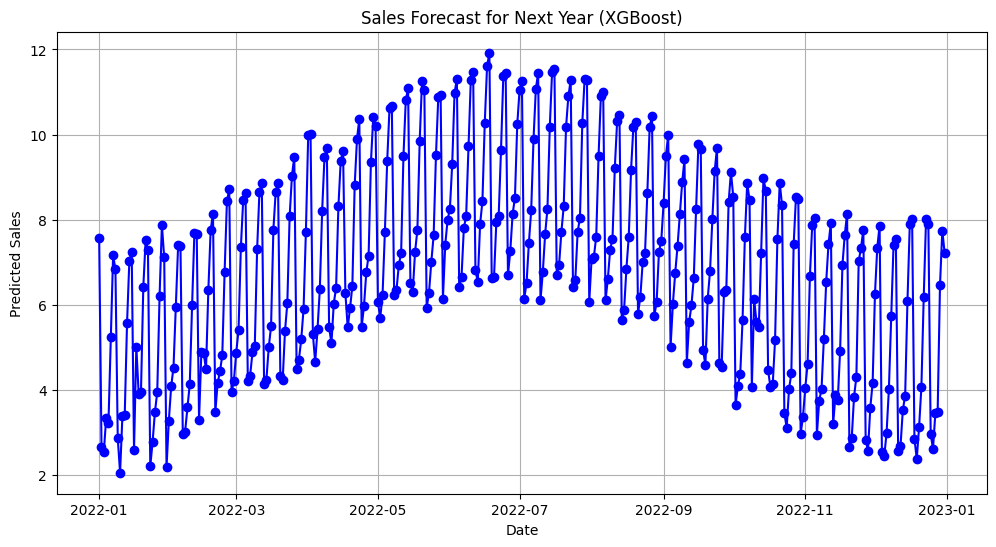

In [ ]:
# Visualize the Forecast
# Plot forecasted sales
plt.figure(figsize=(12, 6))
plt.plot(future_forecasts['date'], future_forecasts['predicted_sales'], color='blue', linestyle='-', marker='o')
plt.title('Sales Forecast for Next Year (XGBoost)')
plt.xlabel('Date')
plt.ylabel('Predicted Sales')
plt.grid()
plt.show()

The graph represents the sales forecast for the next year (2022) using the XGBoost model. below are the observations:

Sales Growth (January to July 2022):

The graph shows a steady upward trend during the first half of the year, suggesting increased sales predictions. This could be tied to seasonal demand, marketing campaigns, or economic growth factors.

Sales Decline (August 2022 to January 2023):

After July, sales predictions begin to taper off, indicating a potential decrease in demand or seasonal slowdowns.

Peak Sales Period:

July emerges as the period of highest predicted sales, making it crucial for planning and capitalizing on high demand.

Lowest Sales Period:

Predictions for January 2023 are the lowest, which might require strategic efforts to sustain revenue during this time.

In [ ]:
#  Deep learning
#  Forecasting using deep learning algorithms
# Use sales amount (price) for predictions
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Select sales amount and date
sales_data = final_df[['date', 'price']].groupby('date').sum().reset_index()

# Ensure the data is sorted by date
sales_data.sort_values('date', inplace=True)

# Normalize the sales data (required for LSTM)
scaler = MinMaxScaler(feature_range=(0, 1))
sales_data['normalized_price'] = scaler.fit_transform(sales_data[['price']])

# Display prepared data
print(sales_data.head())

        date    price  normalized_price
0 2019-01-01  4023.00          0.246762
1 2019-01-02  3074.69          0.154281
2 2019-01-03  4062.71          0.250635
3 2019-01-04  5006.81          0.342705
4 2019-01-05  4927.53          0.334974


In [ ]:
# Split data into training and testing sets
train_size = int(len(sales_data) * 0.8)
train_data = sales_data.iloc[:train_size]
test_data = sales_data.iloc[train_size:]

print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

Training Data Shape: (876, 3)
Testing Data Shape: (220, 3)


In [75]:
# Generate synthetic data for 12 months if no test data exists
synthetic_dates = pd.date_range(start='2021-01-01', end='2021-12-31', freq='D')

# Define the sales range based on `final_df`
price_min = final_df['price'].min()
price_max = final_df['price'].max()

# Generate random sales prices for the synthetic data
synthetic_sales = np.random.uniform(low=price_min, high=price_max, size=len(synthetic_dates))

# Create a DataFrame with synthetic data
synthetic_data = pd.DataFrame({'date': synthetic_dates, 'price': synthetic_sales})


In [76]:
from sklearn.preprocessing import MinMaxScaler

# Normalize synthetic sales data

scaler = MinMaxScaler(feature_range=(0, 1))
synthetic_data['normalized_price'] = scaler.fit_transform(synthetic_data[['price']])

# Check the updated normalized values
print(synthetic_data.head())
combined_data = pd.concat([final_df, synthetic_data], ignore_index=True)
combined_data.sort_values('date', inplace=True)

        date        price  normalized_price
0 2021-01-01  1501.663465          0.674550
1 2021-01-02  2044.464541          0.919250
2 2021-01-03  1497.542829          0.672692
3 2021-01-04  1606.729052          0.721914
4 2021-01-05   889.878459          0.398751


In [84]:
# Create Input Sequences for LSTM
def create_sequences(data, time_steps=7):
    sequences = []
    labels = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:(i + time_steps)])
        labels.append(data[i + time_steps])
    return np.array(sequences), np.array(labels)

# Prepare sequences
time_steps = 7
train_sequences, train_labels = create_sequences(train_data[['normalized_price']].values, time_steps)
test_sequences, test_labels = create_sequences(test_data[['normalized_price']].values, time_steps)

# Reshape for LSTM input

train_sequences = train_sequences.reshape(869, 7, 1)  # Reshape to (samples, timesteps, features)
test_sequences = test_sequences.reshape(213, 7, 1)

print("Updated Train Sequences Shape:", train_sequences.shape)
print("Updated Test Sequences Shape:", test_sequences.shape)


Updated Train Sequences Shape: (869, 7, 1)
Updated Test Sequences Shape: (213, 7, 1)


In [146]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
# Build the LSTM model
model = Sequential([Input(shape=(7,1)),
    LSTM(50, activation='relu', return_sequences=False), # 50 units, input shape: (7 timesteps, 1 feature)
    Dense(1)  # Dense layer for output
])

# Compile the model
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 49s 19ms/step - loss: 0.1445 - val_loss: 0.0551
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0309 - val_loss: 0.0433
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0256 - val_loss: 0.0314
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0202 - val_loss: 0.0184
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0118 - val_loss: 0.0101
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0073 - val_loss: 0.0137
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0055 - val_loss: 0.0086
Epoch 8/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0050 - val_loss: 0.0088
Epoch 9/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0045 - val_loss: 0.0097
Epoch 10/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0042 - val_loss: 0.0073
Epoch 11/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0038 - val_loss: 0.0065
Epoch 12/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0035 - v

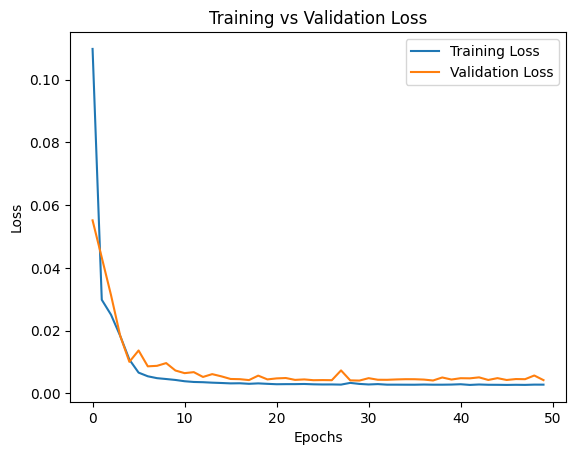

In [147]:
# Train the Model
history = model.fit(
    train_sequences, train_labels,
    validation_data=(test_sequences, test_labels),
    epochs=50,  # Number of epochs
    batch_size=32  # Mini-batch size
)

# Plot training history
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

The above graph effectively demonstrates the difference between training loss and validation loss across epochs. Both losses decrease significantly and stabilize after about 10 epochs, indicating that model is learning effectively. This pattern suggests minimal overfitting, as the validation loss closely follows the training loss

In [149]:
# Make Predictions
predictions = model.predict(test_sequences)
print("Model Input Shape:", model.input_shape)
print("Train Sequences Shape:", train_sequences.shape)
print("Train Labels Shape:", train_labels.shape)
print("Test Sequences Shape:", test_sequences.shape)
# Compare predictions with true labels
for i in range(len(test_labels)):
    # Extract a scalar value correctly from an array before converting to float
    true_label = float(test_labels[i].item())  # Use .item() to get the scalar value from the array
    predicted_label = float(predictions[i][0].item())  # For predictions, extract scalar value properl
    print(f"True: {true_label:.2f}, Predicted: {predicted_label:.2f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Model Input Shape: (None, 7, 1)
Train Sequences Shape: (869, 7, 1)
Train Labels Shape: (869, 1)
Test Sequences Shape: (213, 7, 1)
True: 0.56, Predicted: 0.62
True: 0.74, Predicted: 0.74
True: 0.92, Predicted: 0.85
True: 0.93, Predicted: 0.85
True: 0.48, Predicted: 0.50
True: 0.54, Predicted: 0.50
True: 0.54, Predicted: 0.53
True: 0.67, Predicted: 0.61
True: 0.80, Predicted: 0.76
True: 0.93, Predicted: 0.90
True: 0.95, Predicted: 0.92
True: 0.52, Predicted: 0.51
True: 0.47, Predicted: 0.50
True: 0.57, Predicted: 0.54
True: 0.66, Predicted: 0.64
True: 0.84, Predicted: 0.77
True: 0.97, Predicted: 0.92
True: 0.97, Predicted: 0.96
True: 0.41, Predicted: 0.51
True: 0.51, Predicted: 0.47
True: 0.59, Predicted: 0.55
True: 0.57, Predicted: 0.66
True: 0.79, Predicted: 0.78
True: 0.90, Predicted: 0.92
True: 0.93, Predicted: 0.94
True: 0.50, Predicted: 0.47
True: 0.53, Predicted: 0.48
True: 0.61, Predicted: 0.54
True: 0.65, Predicted: 0.63
True: 0.86, Predicte

In [135]:
# Assuming `test_labels` are the true values and `predictions` are the predicted values
def calculate_mape(true_values, predicted_values):
    # Avoid division by zero
    true_values = np.array(true_values)
    predicted_values = np.array(predicted_values)
    non_zero_indices = true_values != 0

    # MAPE calculation
    mape = np.mean(np.abs((true_values[non_zero_indices] - predicted_values[non_zero_indices]) / true_values[non_zero_indices])) * 100
    return mape

# Example usage
mape = calculate_mape(test_labels, predictions)
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")


Mean Absolute Percentage Error (MAPE): 14.78%


A MAPE of 14.78% is a strong indicator that model's predictions are reasonably accurate. While it doesn't fall into the "excellent"
(<10%) range, it is still considered reliable. It tells as below

Performance: On average, the model's predictions are off by approximately 14.78% compared to the actual values.

Context: Depending on industry and data complexity, a MAPE around 10-15% is often regarded as good.

In [99]:
# Initialize future predictions
future_predictions = []

# Use the last sequence for forecasting
last_sequence = full_sequences[-1].reshape(1, time_steps, 1)

# Generate predictions for the next 90 days
for _ in range(90):
    pred = model.predict(last_sequence, verbose=0)  # Predict the next value
    future_predictions.append(pred[0, 0])  # Append the prediction to the list
    # Update the sequence with the new prediction
    last_sequence = np.append(last_sequence[:, 1:, :], pred.reshape(1, 1, 1), axis=1)

# Convert NumPy floats to Python floats
future_predictions = [float(pred) for pred in future_predictions]

# Format predictions by rounding to 2 decimal places
formatted_predictions = [round(pred, 2) for pred in future_predictions]

# Display predictions
print("Future Forecasts for Next 3 Months:", formatted_predictions)

Future Forecasts for Next 3 Months: [0.61, 0.44, 0.07, 0.03, 0.12, 0.22, 0.4, 0.54, 0.35, 0.07, 0.02, 0.1, 0.23, 0.41, 0.49, 0.28, 0.05, 0.02, 0.1, 0.25, 0.41, 0.43, 0.23, 0.04, 0.03, 0.11, 0.26, 0.39, 0.38, 0.18, 0.04, 0.04, 0.13, 0.27, 0.38, 0.33, 0.15, 0.04, 0.05, 0.15, 0.28, 0.36, 0.28, 0.12, 0.04, 0.07, 0.17, 0.29, 0.33, 0.24, 0.1, 0.05, 0.09, 0.19, 0.29, 0.31, 0.21, 0.1, 0.07, 0.11, 0.2, 0.28, 0.28, 0.18, 0.09, 0.08, 0.13, 0.21, 0.28, 0.25, 0.16, 0.09, 0.09, 0.15, 0.22, 0.27, 0.23, 0.15, 0.1, 0.11, 0.16, 0.23, 0.25, 0.21, 0.14, 0.1, 0.12, 0.18, 0.23, 0.24]


In [101]:
from datetime import datetime, timedelta

# Generate dates for the next 90 days
# Use the last date in the dataset as the start date
start_date = final_df['date'].max()  # This is already a Timestamp
future_dates = [start_date + timedelta(days=i) for i in range(1, 91)]

# Create a DataFrame with dates and predictions
forecast_df = pd.DataFrame({'Date': future_dates, 'Predicted Sales': formatted_predictions})

# Display the first few rows
print(forecast_df.head())

        Date  Predicted Sales
0 2022-01-01             0.61
1 2022-01-02             0.44
2 2022-01-03             0.07
3 2022-01-04             0.03
4 2022-01-05             0.12


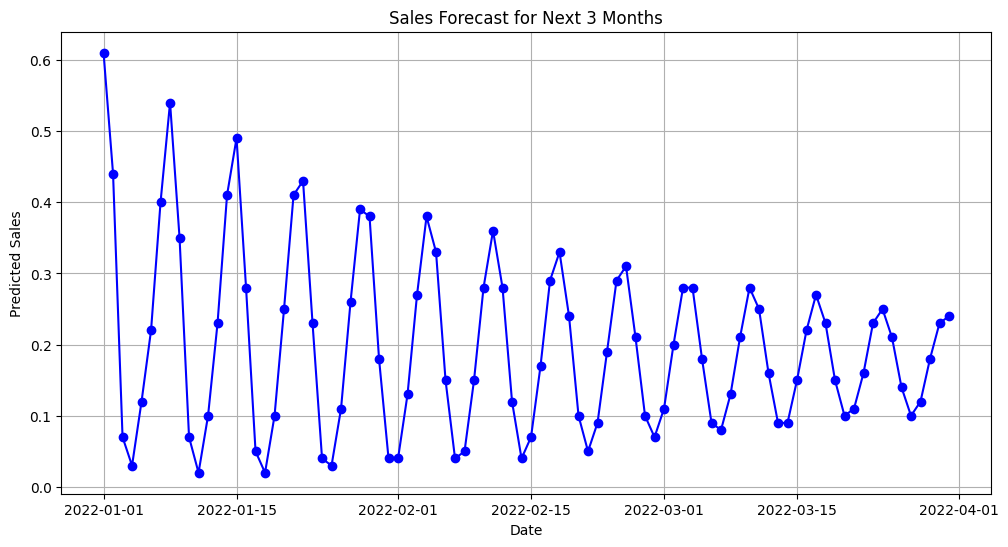

In [102]:
plt.figure(figsize=(12, 6))
plt.plot(forecast_df['Date'], forecast_df['Predicted Sales'], marker='o', linestyle='-', color='blue')
plt.title('Sales Forecast for Next 3 Months')
plt.xlabel('Date')
plt.ylabel('Predicted Sales')
plt.grid()
plt.show()

line graph shows the predicted sales trends for the next three months. The visual highlights fluctuations in sales, with peaks and dips over time. The highest predicted value is around 0.6 at the start of January, while the lowest dips approach 0.0. This forecast can be incredibly useful for identifying key periods for strategic planning.

In [121]:
#Develop another model using the entire series for training, and use it to forecast for the next three
#months
final_df.columns

Index(['date', 'item id', 'item count', 'price', 'item names', 'kcal values',
       'store id', 'store name', 'total_sales', 'day_of_week', 'month',
       'quarter', 'year', 'day_of_month'],
      dtype='object')

In [122]:
#Gated Recurrent Unit (GRU) model. GRU is a type of recurrent neural network (RNN) that is simpler than LSTM but often performs well in forecasting tasks.
#Data Preparation
#Sort Data by Date
final_df = final_df.sort_values(by='date')

In [123]:
# Select Features and Labels
features = final_df[['day_of_week', 'month', 'quarter', 'day_of_month']]
target = final_df['total_sales']

In [124]:
# Normalize Data
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
features_scaled = scaler.fit_transform(features)
target_scaled = scaler.fit_transform(target.values.reshape(-1, 1))

In [125]:
# Create Sequences
import numpy as np

def create_sequences(data, target, time_steps=7):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i+time_steps])
        y.append(target[i+time_steps])
    return np.array(X), np.array(y)

time_steps = 7
X, y = create_sequences(features_scaled, target_scaled, time_steps)

In [126]:
# Train-Test Split
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [127]:
# Build the GRU Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,GRU, Dense

# Define the GRU model with an explicit Input layer
model = Sequential([
    Input(shape=(7, 4)),  # Explicitly specify 7 time steps and 4 features
    GRU(50, activation='relu'),
    Dense(1)  # Final/output layer for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mse')

In [128]:
# Train the Model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 0.0187 - val_loss: 0.0196
Epoch 2/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - loss: 0.0053 - val_loss: 0.0165
Epoch 3/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 0.0049 - val_loss: 0.0138
Epoch 4/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - loss: 0.0047 - val_loss: 0.0152
Epoch 5/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - loss: 0.0045 - val_loss: 0.0151
Epoch 6/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - loss: 0.0043 - val_loss: 0.0153
Epoch 7/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 0.0041 - val_loss: 0.0134
Epoch 8/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - loss: 0.0038 - val_loss: 0.0171
Epoch 9/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - loss: 0.0034 - val_loss: 0.0158
Epoch 10/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 0.0030 - val_loss: 0.0101
Epoch 11/50
2740/2740 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - loss: 0.0027 - val_loss: 0.0125
Epoch 12/50
2740/27

In [129]:
print("X_train Shape:", X_train.shape)  # Should be (samples, 7, 1)
print("X_test Shape:", X_test.shape)

X_train Shape: (87674, 7, 4)
X_test Shape: (21919, 7, 4)


In [130]:
# Evaluate the Model
from sklearn.metrics import mean_absolute_percentage_error

# Make predictions on the test data
y_pred = model.predict(X_test)

# Inverse scale the predictions and actual values
y_test_rescaled = scaler.inverse_transform(y_test)
y_pred_rescaled = scaler.inverse_transform(y_pred)

# Calculate MAPE
mape = mean_absolute_percentage_error(y_test_rescaled, y_pred_rescaled)
print("Mean Absolute Percentage Error (MAPE):", mape)

685/685 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Mean Absolute Percentage Error (MAPE): 0.12809784743589506


A MAPE of 0.128, or approximately 12.81%, indicates that  model's predictions are performing quite well and are relatively accurate compared to the actual values. In many practical applications, a MAPE below 20% is considered good, and below 10% is excellent—so predictions are close to being in the "excellent" range!

This means that on average, model's predictions deviate from the true values by about 12.81%, which is fairly reliable for forecasting.

In [131]:
import tensorflow as tf
import numpy as np

# Ensure 'pred' is a valid NumPy array with expected shape
pred_array = np.array(pred).flatten()  # Flatten to ensure it's a 1D array
pred_array = np.resize(pred_array, (4,))  # Resize to have exactly 4 elements
new_feature = tf.constant(pred_array, dtype=tf.float64)  # Match dtype to 'last_sequence'
print("Shape of pred:", np.array(pred).shape)
print("Content of pred:", pred)
new_feature = tf.reshape(new_feature, (1, 1, 4))  # Reshape to required format

# Reshape 'last_sequence' to match batch dimension and data type
last_sequence = tf.constant(X_test[-1], dtype=tf.float64)  # Ensure data type consistency, Convert 'X_test[-1]' to TensorFlow constant
last_sequence = tf.reshape(last_sequence, (1, last_sequence.shape[0], last_sequence.shape[1]))
print("Updated Last Sequence Shape:", last_sequence.shape)

# Concatenate 'last_sequence' and 'new_feature' with matching data types and shapes

# Concatenate tensors with matching shapes and data types
last_sequence = tf.concat([last_sequence[:, 1:, :], new_feature], axis=1)
print("Last Sequence after Concatenation:", last_sequence.shape)
future_predictions = []

# Forecast for 90 days (3 months)
for _ in range(90):
    # Predict the next value based on the last sequence
    pred = model.predict(last_sequence)

    # Extract the predicted value and update the sequence
    # Process and update 'new_feature'
    pred_array = np.array(pred).flatten()
    pred_array = np.resize(pred_array, (4,))
    new_feature = tf.constant(pred_array, dtype=tf.float64)
    new_feature = tf.reshape(new_feature, (1, 1, 4))  # Ensure proper shape
    last_sequence = tf.concat([last_sequence[:, 1:, :], new_feature], axis=1)

    # Add the prediction to the results
    future_predictions.append(pred[0, 0])

# Rescale predictions using the scaler
future_predictions_rescaled = scaler.inverse_transform(np.array(future_predictions).reshape(-1, 1))
print("Rescaled Future Predictions:", future_predictions_rescaled)

Shape of pred: (1, 1)
Content of pred: [[0.5935725]]
Updated Last Sequence Shape: (1, 7, 4)
Last Sequence after Concatenation: (1, 7, 4)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s

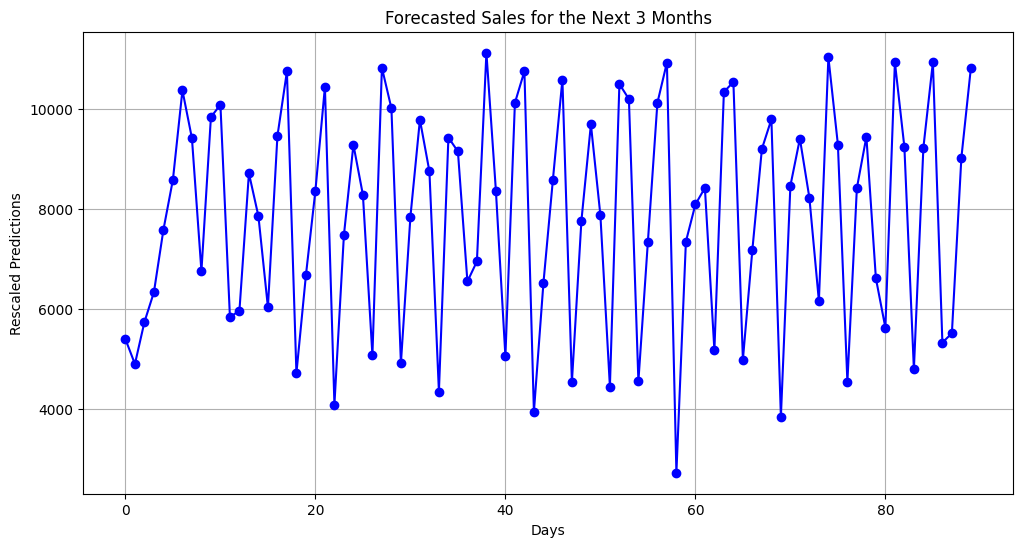

In [ ]:
# Analyze the Forecast
plt.figure(figsize=(12, 6))
plt.plot(future_predictions_rescaled, color='blue', marker='o', linestyle='-')
plt.title("Forecasted Sales for the Next 3 Months")
plt.xlabel("Days")
plt.ylabel("Rescaled Predictions")
plt.grid()
plt.show()

This graph beautifully illustrates forecasted sales for the next three months with daily fluctuations captured in detail. Peaks represent periods of high predicted sales, while troughs highlight the lows in demand. It offers valuable insights into the variations across the days, showing the importance of planning around periods with high or low sales.